In [9]:
# %% 1. CONFIGURACIÓN Y CARGA DE DATOS
import os
import re
import warnings
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.api.types import is_numeric_dtype, is_datetime64_any_dtype
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.model_selection import KFold
from sklearn.neighbors import BallTree
 
warnings.filterwarnings("ignore")
 
# MIOS: LightGBM es opcional. Si está instalado se agrega al ensamble; si no, el código sigue igual.
#       Para instalarlo: %pip install lightgbm
try:
    import lightgbm as lgb
    HAY_LGBM = True
except ImportError:
    HAY_LGBM = False
 
# MIOS: rutas (las mismas de mi estructura de carpetas). PuntosInteres.csv es OPCIONAL: si no
#       existe en data/raw el código simplemente no crea las variables de puntos de interés.
RUTA_TRAIN = '../data/raw/entrenamiento_precios_vivienda.xlsx'
RUTA_TEST = '../data/raw/testeo_precios_vivienda.xlsx'
RUTA_POI = '../data/raw/PuntosInteres.csv'
RUTA_SALIDA = '../data/base_evaluada.csv'
 
TARGET = 'valor_total_avaluo'
SEMILLA = 42
MAX_CARDINALIDAD = 100   # MIOS: categóricas con más de 100 niveles se descartan (texto libre, direcciones, etc.)
N_FOLDS = 5
 
np.random.seed(SEMILLA)
pd.options.display.float_format = '{:,.2f}'.format
 
# MIOS: requiere openpyxl para leer Excel (pip install openpyxl)
df_train_raw = pd.read_excel(RUTA_TRAIN)
df_test_raw = pd.read_excel(RUTA_TEST)
 
print("--- Dimensiones ---")
print(f"Entrenamiento: {df_train_raw.shape[0]} filas, {df_train_raw.shape[1]} columnas")
print(f"Prueba:        {df_test_raw.shape[0]} filas, {df_test_raw.shape[1]} columnas")

--- Dimensiones ---
Entrenamiento: 12857 filas, 221 columnas
Prueba:        5385 filas, 211 columnas


In [10]:
# %% 2. FUGA DE DATOS (DATA LEAKAGE)
# MIOS: las columnas que existen en entrenamiento pero NO en testeo (áreas valoradas, UVR, etc.)
#       se calculan a partir del avalúo o junto con él. Si las usara como variables, el modelo
#       "haría trampa" y en testeo no estarían disponibles. Solo se conserva el target.
cols_exclusivas = set(df_train_raw.columns) - set(df_test_raw.columns)
assert TARGET in cols_exclusivas, "El target debería existir solo en entrenamiento"
cols_fuga = sorted(c for c in cols_exclusivas if c != TARGET)
print(f"\nColumnas eliminadas por fuga de datos ({len(cols_fuga)}): {cols_fuga}")
 
df_train = df_train_raw.drop(columns=cols_fuga).copy()
df_test = df_test_raw.copy()
 


Columnas eliminadas por fuga de datos (9): ['valor_area_construccion', 'valor_area_deposito', 'valor_area_garaje', 'valor_area_libre', 'valor_area_otros', 'valor_area_privada', 'valor_area_terreno', 'valor_avaluo_en_uvr', 'valor_uvr']



--- Diagnóstico del target ---
Nulos originales:                         0
NaN tras pd.to_numeric (lo que perdía):   3448
NaN tras parsear_numero (parser propio):  0
Valores <= 0:                             160
Ejemplos de textos que pandas no entendía: ['71995500,00', '87094000,08', '76151500,00', '78090000,0', '61205000,00', '215503189,52', '1608208000,0', '1195946350,00', '812313000,00', '85152400,00', '1289450800,00', '195524450,00', '83650808,88', '133100000,00', '132604500,00']

Filas de entrenamiento utilizables: 12697 de 12857
count              12,697.00
mean        2,403,730,229.00
std        79,660,447,083.87
min                     3.00
25%           116,030,720.00
50%           178,874,000.00
75%           296,586,000.00
max     5,744,320,000,008.00
Name: y, dtype: float64


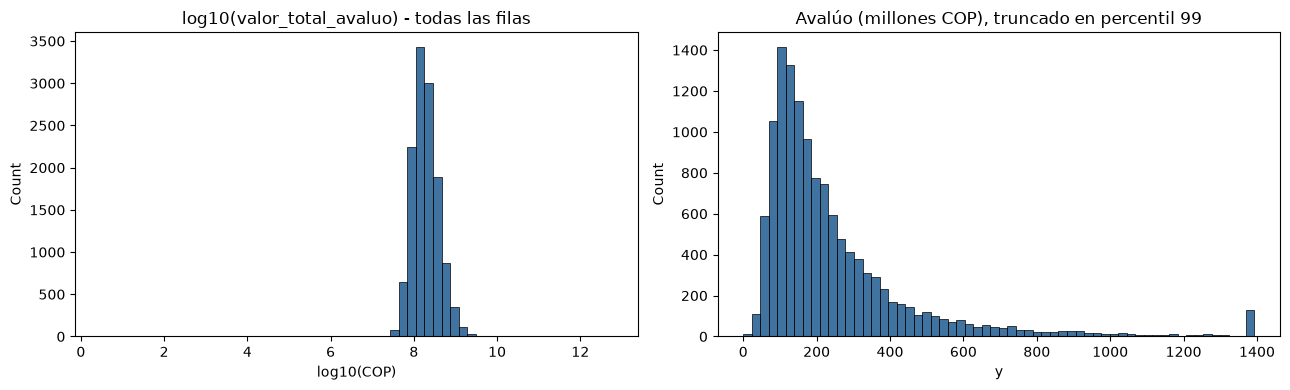

In [11]:
# %% 3. LIMPIEZA DE LA VARIABLE OBJETIVO
# MIOS: en mi primer intento usé pd.to_numeric(errors='coerce') y perdí ~28% de las filas (12.857 -> 9.249)
#       porque el target venía como texto (separadores de miles/decimales mezclados). Además el mínimo
#       era 3 y el máximo 5,7 billones, señal de problemas de formato. Aquí hago un parser propio que
#       entiende formatos colombianos ("1.234.567,89"), anglosajones ("1,234,567.89"), con "$", etc.
 
_RE_NUM = re.compile(r'^-?\d[\d.,]*$')
_RE_CIENT = re.compile(r'^-?\d+(\.\d+)?[eE][+-]?\d+$')
_RE_TOKEN = re.compile(r'-?\d+(?:[.,]\d+)*')
 
 
def parsear_numero(x):
    """Convierte texto o número a float interpretando separadores de miles y decimales."""
    if x is None:
        return np.nan
    if isinstance(x, (int, float, np.integer, np.floating)):
        return float(x)
    s = str(x).strip().replace('$', '').replace(' ', '').replace('\u00a0', '')
    if s == '' or s.lower() in ('nan', 'none', 'null', 'n/a', 'nd', 'n/d', '-', '<na>'):
        return np.nan
    if _RE_CIENT.match(s):
        return float(s)
    if not _RE_NUM.match(s):
        return np.nan
    tiene_punto, tiene_coma = '.' in s, ',' in s
    if tiene_punto and tiene_coma:
        # MIOS: el separador que aparece de último es el decimal
        if s.rfind(',') > s.rfind('.'):
            s = s.replace('.', '').replace(',', '.')   # 1.234.567,89
        else:
            s = s.replace(',', '')                      # 1,234,567.89
    elif tiene_punto:
        partes = s.split('.')
        if len(partes) > 2:
            s = s.replace('.', '')                      # 1.234.567
        elif len(partes[1]) == 3 and len(partes[0].lstrip('-')) <= 3:
            s = s.replace('.', '')                      # 177.526 (miles)
    elif tiene_coma:
        partes = s.split(',')
        if len(partes) > 2:
            s = s.replace(',', '')                      # 1,234,567
        elif len(partes[1]) == 3 and len(partes[0].lstrip('-')) <= 3:
            s = s.replace(',', '')                      # 177,526 (miles)
        else:
            s = s.replace(',', '.')                     # 85,5 (decimal)
    try:
        return float(s)
    except ValueError:
        return np.nan
 
 
def parsear_numero_tolerante(x):
    """Igual que parsear_numero pero extrae el primer número de textos tipo '85,5 m2'."""
    v = parsear_numero(x)
    if not np.isnan(v):
        return v
    m = _RE_TOKEN.search(str(x))
    return parsear_numero(m.group(0)) if m else np.nan
 
 
# --- Diagnóstico: ¿qué hacía pd.to_numeric y qué hace mi parser? ---
t_pandas = pd.to_numeric(df_train[TARGET], errors='coerce')
t_propio = df_train[TARGET].map(parsear_numero)
print("\n--- Diagnóstico del target ---")
print(f"Nulos originales:                         {df_train[TARGET].isna().sum()}")
print(f"NaN tras pd.to_numeric (lo que perdía):   {t_pandas.isna().sum()}")
print(f"NaN tras parsear_numero (parser propio):  {t_propio.isna().sum()}")
print(f"Valores <= 0:                             {(t_propio <= 0).sum()}")
ejemplos_raros = df_train.loc[t_pandas.isna() & df_train[TARGET].notna(), TARGET].head(15).tolist()
print(f"Ejemplos de textos que pandas no entendía: {ejemplos_raros}")
 
# MIOS: solo se descartan filas con target nulo o <= 0 (no se puede aprender de un precio inexistente).
df_train['y'] = t_propio
df_train = df_train.drop(columns=[TARGET])
df_train = df_train[df_train['y'] > 0].reset_index(drop=True)
print(f"\nFilas de entrenamiento utilizables: {len(df_train)} de {len(df_train_raw)}")
print(df_train['y'].describe())
 
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(np.log10(df_train['y']), bins=60, ax=ax[0], color='#004481')
ax[0].set_title('log10(valor_total_avaluo) - todas las filas')
ax[0].set_xlabel('log10(COP)')
sns.histplot(df_train['y'].clip(upper=df_train['y'].quantile(0.99)) / 1e6, bins=60, ax=ax[1], color='#004481')
ax[1].set_title('Avalúo (millones COP), truncado en percentil 99')
plt.tight_layout()
plt.show()

In [12]:
# %% 4. FUNCIONES DE LIMPIEZA Y CONSTRUCCIÓN DE VARIABLES
# MIOS: todo se hace con funciones para aplicar EXACTAMENTE la misma transformación a entrenamiento y
#       a testeo (en mi versión anterior imputaba el test con la mediana del propio test, lo cual es
#       inconsistente). Aquí todo lo "aprendido" (columnas, categorías) sale del entrenamiento.
 
PALABRAS_EXCLUIR = ['matricula', 'direccion', 'telefono', 'cedula']   # identificadores / datos personales
R_TIERRA_KM = 6371.0
 
 
def es_texto(s):
    return (not is_numeric_dtype(s)) and (not is_datetime64_any_dtype(s))
 
 
def es_excluida(nombre):
    n = nombre.lower()
    return n == 'id' or any(k in n for k in PALABRAS_EXCLUIR)
 
 
def parsear_coord(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, float, np.integer, np.floating)):
        return float(x)
    try:
        return float(str(x).strip().replace(',', '.'))
    except ValueError:
        return np.nan
 
 
def limpiar_coordenadas(df):
    """Latitud/Longitud a número y se invalidan las que caen fuera de Colombia."""
    if 'Latitud' not in df.columns or 'Longitud' not in df.columns:
        return df
    df['Latitud'] = df['Latitud'].map(parsear_coord)
    df['Longitud'] = df['Longitud'].map(parsear_coord)
    df.loc[df['Longitud'] > 0, 'Longitud'] *= -1    # longitud con signo perdido
    fuera = ~(df['Latitud'].between(-5, 14) & df['Longitud'].between(-80, -66))
    df.loc[fuera, ['Latitud', 'Longitud']] = np.nan
    return df
 
 
def norm_cat(s):
    """Normaliza categorías (espacios, mayúsculas) y deja 'sin_dato' para nulos."""
    return s.astype(object).where(s.notna(), 'Sin_Dato').astype(str).str.strip().str.lower()
 
 
def limpiar_nombre(n):
    return re.sub(r'[^0-9a-zA-Z_]', '_', str(n))
 
 
def cargar_arboles_poi(ruta):
    """Lee PuntosInteres.csv (opcional) y construye un BallTree por categoría para consultas rápidas."""
    if not os.path.exists(ruta):
        print("PuntosInteres.csv no encontrado: se omiten las variables de puntos de interés.")
        return {}
    try:
        poi = pd.read_csv(ruta)
    except UnicodeDecodeError:
        poi = pd.read_csv(ruta, encoding='latin-1')
    # MIOS: según el enunciado las dos primeras columnas son longitud y latitud, pero no dice el orden.
    #       En Colombia la longitud es negativa (~ -75) y la latitud positiva (~ 6), así que lo detecto.
    a = poi.iloc[:, 0].map(parsear_coord)
    b = poi.iloc[:, 1].map(parsear_coord)
    lon, lat = (a, b) if a.median() < 0 else (b, a)
    p = pd.DataFrame({'lat': lat, 'lon': lon, 'cat': poi.iloc[:, 2].astype(str)}).dropna()
    p = p[p['lat'].between(-5, 14) & p['lon'].between(-80, -66)]
    arboles = {}
    for cat, g in p.groupby('cat'):
        if len(g) >= 20:   # MIOS: categorías con muy pocos puntos no aportan señal estable
            arboles[limpiar_nombre(cat)[:30]] = BallTree(np.radians(g[['lat', 'lon']].values), metric='haversine')
    print(f"Categorías de puntos de interés usadas: {len(arboles)}")
    return arboles
 
 
def features_poi(df, arboles):
    """Por categoría: distancia al punto más cercano (km) y cantidad de puntos a menos de 1 km."""
    out = {}
    if not arboles or 'Latitud' not in df.columns:
        return pd.DataFrame(index=df.index)
    ok = df[['Latitud', 'Longitud']].notna().all(axis=1).values
    coords = np.radians(df.loc[ok, ['Latitud', 'Longitud']].values)
    for cat, tree in arboles.items():
        d = np.full(len(df), np.nan)
        n = np.full(len(df), np.nan)
        if ok.any():
            dist, _ = tree.query(coords, k=1)
            d[ok] = dist[:, 0] * R_TIERRA_KM
            n[ok] = tree.query_radius(coords, r=1.0 / R_TIERRA_KM, count_only=True)
        out['poi_dist_' + cat] = d
        out['poi_n1km_' + cat] = n
    return pd.DataFrame(out, index=df.index)
 
 
def transformar_base(df, plan):
    """Transformaciones sin estado: usa solo las listas guardadas en 'plan'."""
    df = df.copy()
    df = limpiar_coordenadas(df)
    for c in df.columns:
        if df[c].dtype == bool:
            df[c] = df[c].astype(int)
    # MIOS: números escondidos en texto (áreas, cupos, estrato...) -> numéricos
    for c in plan['cols_num_ocultas']:
        if c in df.columns:
            df[c] = df[c].map(parsear_numero)
    for c in plan['cols_area_tol']:
        if c in df.columns:
            df[c] = df[c].map(parsear_numero_tolerante)
    # MIOS: de los textos libres de observaciones no uso el contenido, pero sí su longitud y nº de palabras
    #       (un inmueble con más descripción suele ser más grande/complejo).
    for c in plan['cols_texto_len']:
        if c in df.columns:
            t = df[c].fillna('').astype(str)
            df['len_' + c] = t.str.len()
            df['pal_' + c] = t.str.split().str.len()
    # MIOS: las fechas se vuelven un número (año + fracción) porque el tiempo captura inflación del mercado
    for c in plan['cols_fecha']:
        if c in df.columns:
            f = df[c] if is_datetime64_any_dtype(df[c]) else pd.to_datetime(df[c], errors='coerce', dayfirst=True)
            df['t_' + c] = f.dt.year + (f.dt.month - 1) / 12.0
    # MIOS: variables geográficas derivadas de puntos de interés (si el archivo existe)
    poi = features_poi(df, plan['poi_arboles'])
    if not poi.empty:
        df = pd.concat([df, poi], axis=1)
    return df
 
 
def ajustar_plan(df):
    """Decide (SOLO con entrenamiento) qué columnas se usan y cómo se codifican las categóricas."""
    plan = {}
    cols_texto = [c for c in df.columns if es_texto(df[c])]
    plan['cols_texto_len'] = [c for c in cols_texto if 'observ' in c.lower()]
    plan['cols_fecha'] = [c for c in df.columns if 'fecha' in c.lower()]
 
    # MIOS: detectar columnas de texto que en realidad son números (>= 90% de sus valores se parsean)
    plan['cols_num_ocultas'], plan['cols_area_tol'] = [], []
    candidatas = [c for c in cols_texto
                  if c not in plan['cols_texto_len'] and c not in plan['cols_fecha']
                  and not es_excluida(c) and c not in ('Latitud', 'Longitud')]
    for c in candidatas:
        v = df[c].dropna()
        if len(v) == 0:
            continue
        if v.map(parsear_numero).notna().mean() >= 0.9:
            plan['cols_num_ocultas'].append(c)
        elif 'area' in c.lower() and v.map(parsear_numero_tolerante).notna().mean() >= 0.9:
            plan['cols_area_tol'].append(c)   # ej. "85,5 m2"
    print(f"Columnas de texto convertidas a número: {plan['cols_num_ocultas']}")
    print(f"Columnas de área con unidades en el texto: {plan['cols_area_tol']}")
 
    plan['poi_arboles'] = cargar_arboles_poi(RUTA_POI)
    df_aug = transformar_base(df, plan)
 
    # MIOS: selección de variables: numéricas no constantes + categóricas con 2..100 niveles.
    #       Se descartan id, identificadores, textos libres y columnas originales de fecha/observaciones.
    excluir = {'id', 'y'} | set(plan['cols_texto_len']) | set(plan['cols_fecha'])
    cols_num, cols_cat = [], []
    for c in df_aug.columns:
        if c in excluir or es_excluida(c):
            continue
        s = df_aug[c]
        if is_numeric_dtype(s):
            if s.nunique(dropna=True) > 1:
                cols_num.append(c)
        elif not is_datetime64_any_dtype(s):
            n = s.nunique(dropna=True)
            if 2 <= n <= MAX_CARDINALIDAD:
                cols_cat.append(c)
    plan['cols_num'], plan['cols_cat'] = cols_num, cols_cat
 
    # MIOS: codificación ordinal de categóricas aprendida en entrenamiento. Categorías nuevas en test -> NaN
    #       (los árboles de boosting manejan NaN de forma nativa, no necesito imputar con medianas).
    plan['mapas_cat'] = {}
    for c in cols_cat:
        niveles = sorted(norm_cat(df_aug[c]).unique())
        plan['mapas_cat'][c] = {v: i for i, v in enumerate(niveles)}
 
    nombres, vistos = [], {}
    for c in cols_num + cols_cat:
        n = limpiar_nombre(c)
        vistos[n] = vistos.get(n, 0) + 1
        nombres.append(n if vistos[n] == 1 else f"{n}_{vistos[n]}")
    plan['nombres_modelo'] = nombres
    plan['mascara_cat'] = [False] * len(cols_num) + [True] * len(cols_cat)
    return plan, df_aug
 
 
def construir_X(df_aug, plan):
    """Matriz numérica final (mismas columnas y mismo orden en entrenamiento y testeo)."""
    X = pd.DataFrame(index=df_aug.index)
    for c in plan['cols_num']:
        X[c] = pd.to_numeric(df_aug[c], errors='coerce') if c in df_aug.columns else np.nan
    for c in plan['cols_cat']:
        X[c] = norm_cat(df_aug[c]).map(plan['mapas_cat'][c]).astype(float) if c in df_aug.columns else np.nan
    X = X.replace([np.inf, -np.inf], np.nan)
    X.columns = plan['nombres_modelo']
    return X

In [13]:
 
# %% 5. PLAN DE VARIABLES (APRENDIDO SOLO CON ENTRENAMIENTO)
# MIOS: con respecto a mi versión anterior, ya NO elimino columnas por contener "descripcion" en el
#       nombre. Eso borraba descripcion_uso_inmueble / tipo / clase, que son categorías cortas y
#       muy informativas. Ahora el criterio es la cardinalidad (nº de niveles), no el nombre.
y = df_train['y'].values
plan, df_train_aug = ajustar_plan(df_train)
X = construir_X(df_train_aug, plan)
 
print(f"\nVariables numéricas: {len(plan['cols_num'])} | categóricas: {len(plan['cols_cat'])} | total: {X.shape[1]}")
print("% de nulos por variable (top 10):")
print((X.isna().mean().sort_values(ascending=False).head(10) * 100).round(1))

Columnas de texto convertidas a número: ['estrato', 'unidades', 'contadores_agua', 'contadores_luz', 'accesorios', 'area_valorada', 'numero_piso', 'numero_de_edificios', 'vetustez', 'pisos_bodega', 'habitaciones', 'estar_habitacion', 'cuarto_servicio', 'closet', 'sala', 'comedor', 'bano_privado', 'numero_total_de_garajes', 'total_cupos_parquedaro', 'numero_garaje_1', 'numero_garaje_2', 'garaje_cubierto_2', 'garaje_doble_2', 'garaje_paralelo_2', 'garaje_servidumbre_2', 'numero_garaje_3', 'garaje_cubierto_3', 'garaje_doble_3', 'garaje_paralelo_3', 'garaje_servidumbre_3', 'numero_garaje_4', 'garaje_cubierto_4', 'garaje_doble_4', 'garaje_paralelo_4', 'garaje_servidumbre_4', 'garaje_cubierto_5', 'garaje_doble_5', 'garaje_paralelo_5', 'garaje_servidumbre_5', 'numero_total_depositos', 'numero_deposito_1', 'numero_deposito_2', 'numero_deposito_3', 'numero_deposito_4', 'metodo_valuacion_1', 'concepto_del_metodo_1', 'metodo_valuacion_2', 'concepto_del_metodo_2', 'metodo_valuacion_3', 'concepto_d


Columna de área usada para precio por m2: area_privada


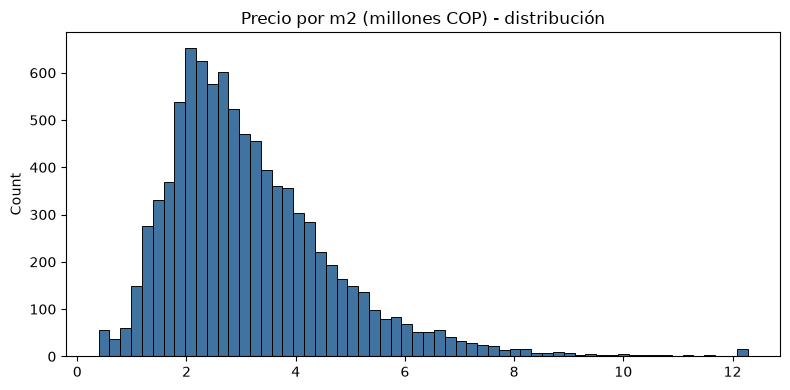

Filas marcadas como atípicas: 282 (2.2%). Se usan 12415 para entrenar.


In [14]:
# %% 6. VALORES ATÍPICOS (SOLO PARA ENTRENAR)
# MIOS: antes recortaba el percentil 1-99 del avalúo y además medía el error sobre esos mismos datos
#       "limpios", lo cual da un MAPE optimista. Ahora marco como atípicos: (a) avalúos en los extremos
#       y (b) precios por m2 imposibles (ej. avalúo de 3 pesos). Esas filas NO se usan para entrenar,
#       pero SÍ las incluyo al reportar el error de validación (versión "todo") para ser honesto.
col_area = next((c for c in ['area_privada', 'area_valorada']
                 if c in df_train_aug.columns and is_numeric_dtype(df_train_aug[c])
                 and (df_train_aug[c] > 0).mean() > 0.5), None)
print(f"\nColumna de área usada para precio por m2: {col_area}")
 
atipico = np.zeros(len(df_train), dtype=bool)
lo_y, hi_y = np.quantile(y, [0.005, 0.995])
atipico |= (y < lo_y) | (y > hi_y)
if col_area is not None:
    area = df_train_aug[col_area].where(df_train_aug[col_area] > 0).values
    precio_m2 = y / area
    ok = ~np.isnan(precio_m2)
    lo_m2, hi_m2 = np.quantile(precio_m2[ok], [0.01, 0.99])
    atipico |= ok & ((precio_m2 < lo_m2) | (precio_m2 > hi_m2))
    plt.figure(figsize=(8, 4))
    sns.histplot(np.clip(precio_m2[ok], lo_m2 / 2, hi_m2 * 1.5) / 1e6, bins=60, color='#004481')
    plt.title('Precio por m2 (millones COP) - distribución')
    plt.tight_layout()
    plt.show()
 
print(f"Filas marcadas como atípicas: {atipico.sum()} ({atipico.mean():.1%}). Se usan {(~atipico).sum()} para entrenar.")
 

In [15]:

# %% 7. MODELOS Y VALIDACIÓN CRUZADA
# MIOS: decisiones clave de modelamiento:
#   * Predigo log(avalúo) y regreso con exp(): el MAPE es un error RELATIVO y los precios tienen cola larga;
#     en escala logarítmica el modelo trata igual un error de 10% en una casa barata y en una cara.
#   * Modelos: HistGradientBoosting (sklearn), RandomForest y, si está instalado, LightGBM. Luego los
#     promedio (ensamble) porque casi siempre reduce el error.
#   * Validación cruzada de 5 folds para tener una estimación estable del MAPE.
y_log = np.log(y)
MODELOS = ['hgb', 'rf'] + (['lgbm'] if HAY_LGBM else [])
 
 
def crear_modelo(nombre):
    if nombre == 'hgb':
        return HistGradientBoostingRegressor(
            learning_rate=0.05, max_iter=800, max_leaf_nodes=31, min_samples_leaf=20,
            l2_regularization=1.0, early_stopping=True, validation_fraction=0.1,
            n_iter_no_change=40, categorical_features=np.array(plan['mascara_cat']) if any(plan['mascara_cat']) else None,
            random_state=SEMILLA)
    if nombre == 'rf':
        return RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5,
                                     n_jobs=-1, random_state=SEMILLA)
    if nombre == 'lgbm':
        return lgb.LGBMRegressor(n_estimators=800, learning_rate=0.03, num_leaves=31, subsample=0.8,
                                 subsample_freq=1, colsample_bytree=0.7, random_state=SEMILLA,
                                 n_jobs=-1, verbose=-1)
    raise ValueError(nombre)
 
 
def ajustar(nombre, X_tr, y_tr):
    m = crear_modelo(nombre)
    if nombre == 'rf':
        m.fit(X_tr.fillna(-1), y_tr)          # MIOS: RandomForest no acepta NaN
    elif nombre == 'lgbm':
        cats = [n for n, esc in zip(plan['nombres_modelo'], plan['mascara_cat']) if esc]
        m.fit(X_tr, y_tr, categorical_feature=cats if cats else 'auto')
    else:
        m.fit(X_tr, y_tr)
    return m
 
 
def predecir(nombre, m, X_):
    return m.predict(X_.fillna(-1) if nombre == 'rf' else X_)
 
 
def mape(y_real, y_pred):
    return mean_absolute_percentage_error(y_real, y_pred)
 
 
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)
oof = {n: np.zeros(len(X)) for n in MODELOS}   # predicciones fuera de muestra (en log)
for k, (idx_tr, idx_va) in enumerate(kf.split(X), start=1):
    idx_tr = idx_tr[~atipico[idx_tr]]           # MIOS: entreno sin atípicos; valido con TODAS las filas del fold
    for n in MODELOS:
        m = ajustar(n, X.iloc[idx_tr], y_log[idx_tr])
        oof[n][idx_va] = predecir(n, m, X.iloc[idx_va])
    print(f"Fold {k}/{N_FOLDS} listo")
 
oof['ensamble'] = np.mean([oof[n] for n in MODELOS], axis=0)
 
filas = []
for n, p_log in oof.items():
    p = np.exp(p_log)
    ape = np.abs(p - y) / y
    filas.append({'modelo': n,
                  'MAPE_todo': mape(y, p),
                  'MAPE_sin_atipicos': mape(y[~atipico], p[~atipico]),
                  'Mediana_APE': np.median(ape)})
resultados = pd.DataFrame(filas).set_index('modelo').sort_values('MAPE_sin_atipicos')
print("\n--- Validación cruzada (fuera de muestra) ---")
print(resultados.map(lambda v: f"{v:.2%}"))
 
# MIOS: elijo por MAPE sobre filas "normales" (las atípicas son errores de captura imposibles de predecir),
#       pero reporto también el MAPE de todo para no ocultar nada en la sustentación.
# MIOS: ojo al leer "MAPE_todo": un solo avalúo registrado como 3 pesos (cuando el inmueble vale 300 millones)
#       genera un error porcentual de millones de % y dispara el promedio. Por eso también muestro la
#       mediana del error (Mediana_APE), que no se ve afectada, y el MAPE sin atípicos. Si el testeo tiene
#       filas así, el MAPE oficial las incluirá y ningún modelo puede acertarlas.
n_imposibles = int((y < 1e6).sum())
print(f"\nFilas de entrenamiento con avalúo < 1 millón de COP (probables errores de captura): {n_imposibles}")
mejor = resultados.index[0]
print(f"\nMejor configuración: {mejor}")

Fold 1/5 listo
Fold 2/5 listo
Fold 3/5 listo
Fold 4/5 listo
Fold 5/5 listo

--- Validación cruzada (fuera de muestra) ---
           MAPE_todo MAPE_sin_atipicos Mediana_APE
modelo                                            
hgb       249474.08%            14.13%      10.77%
ensamble  236269.61%            14.34%      10.80%
rf        223822.65%            15.97%      12.02%

Filas de entrenamiento con avalúo < 1 millón de COP (probables errores de captura): 3

Mejor configuración: hgb


Factor de calibración: 0.975 | MAPE sin atípicos antes 14.13% -> después 13.98%


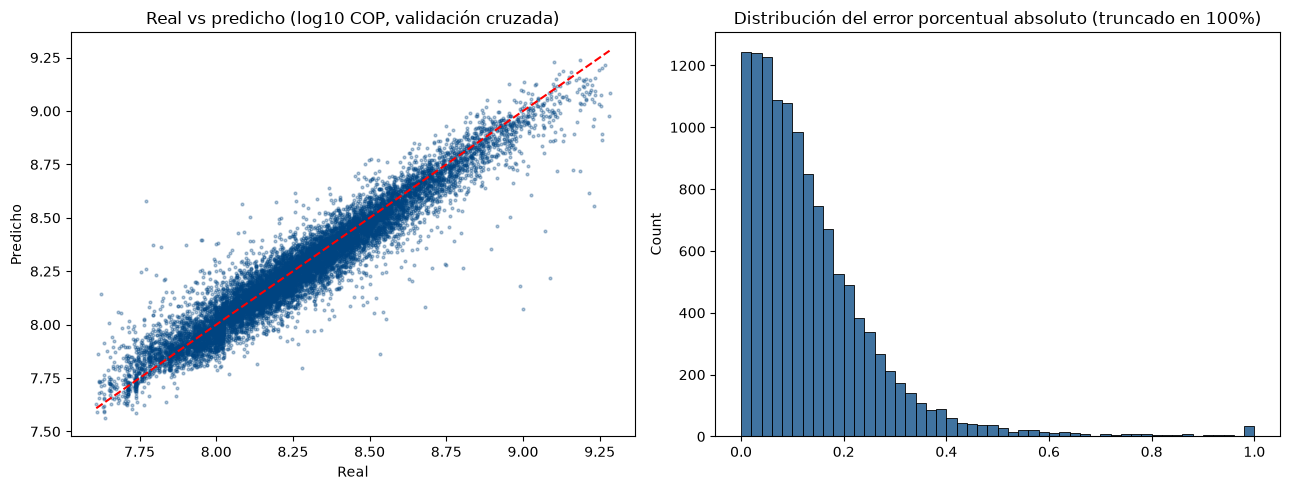

In [16]:

# %% 8. CALIBRACIÓN, MODELO FINAL Y PREDICCIONES
# MIOS: el MAPE penaliza más sobrestimar que subestimar, así que multiplico las predicciones por un factor
#       c (cercano a 1) que minimiza el MAPE fuera de muestra. Es un ajuste de un solo parámetro, de bajo riesgo.
p_best = np.exp(oof[mejor])
factores = np.arange(0.85, 1.10, 0.005)
errores = [mape(y[~atipico], c * p_best[~atipico]) for c in factores]
factor = float(factores[int(np.argmin(errores))])
print(f"Factor de calibración: {factor:.3f} | MAPE sin atípicos antes {min(errores[0], mape(y[~atipico], p_best[~atipico])):.2%} -> después {min(errores):.2%}")
 
# Gráficos de diagnóstico de la validación
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
lim = np.log10([y[~atipico].min(), y[~atipico].max()])
ax[0].scatter(np.log10(y[~atipico]), np.log10(factor * p_best[~atipico]), s=4, alpha=0.3, color='#004481')
ax[0].plot(lim, lim, 'r--')
ax[0].set_title('Real vs predicho (log10 COP, validación cruzada)')
ax[0].set_xlabel('Real'); ax[0].set_ylabel('Predicho')
ape_plot = np.abs(factor * p_best[~atipico] - y[~atipico]) / y[~atipico]
sns.histplot(np.clip(ape_plot, 0, 1), bins=50, ax=ax[1], color='#004481')
ax[1].set_title('Distribución del error porcentual absoluto (truncado en 100%)')
plt.tight_layout()
plt.show()
 
# MIOS: modelo final = se reentrena con el 100% de las filas no atípicas (no solo el 80% como antes).
usar = MODELOS if mejor == 'ensamble' else [mejor]
modelos_finales = {n: ajustar(n, X.loc[~atipico], y_log[~atipico]) for n in usar}
 
# MIOS: el test se transforma con el MISMO plan (columnas, categorías, parseos) aprendido en entrenamiento.
df_test_aug = transformar_base(df_test, plan)
X_test = construir_X(df_test_aug, plan)
assert list(X_test.columns) == list(X.columns), "Las columnas de test y entrenamiento no coinciden"
 
pred_log = np.mean([predecir(n, m, X_test) for n, m in modelos_finales.items()], axis=0)
pred = np.exp(pred_log) * factor
 
# MIOS: red de seguridad: no permito predicciones fuera del rango observado de avalúos normales y
#       reemplazo cualquier NaN/inf por la mediana (el entregable no admite nulos).
pred = np.clip(pred, y[~atipico].min(), y[~atipico].max())
pred = np.where(np.isfinite(pred), pred, np.median(y[~atipico]))
 
# Importancia de variables (del RandomForest, que entrego como referencia de interpretabilidad)
if 'rf' in modelos_finales:
    imp = pd.Series(modelos_finales['rf'].feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
    plt.figure(figsize=(9, 6))
    sns.barplot(x=imp.values, y=imp.index, color='#004481')
    plt.title('Top 15 variables que más explican el avalúo (RandomForest)')
    plt.xlabel('Importancia')
    plt.tight_layout()
    plt.show()
    print(imp.round(4))
# MIOS: en mi versión anterior 'id' aparecía entre las 10 más importantes, lo cual es un identificador sin
#       significado. Ahora se excluye desde el principio (ver es_excluida).

In [17]:

# %% 9. ENTREGABLE Y VALIDACIONES
# MIOS: el archivo debe llamarse base_evaluada.csv, con columnas id y valor_total_avaluo, separado por comas,
#       sin nulos y con los mismos ids del archivo de testeo. En mi versión anterior, si no existía 'id'
#       se inventaba un índice; ahora eso sería un error explícito para no entregar algo incorrecto.
assert 'id' in df_test.columns, "El archivo de testeo debe tener la columna id"
entregable = pd.DataFrame({'id': df_test['id'].values, TARGET: pred})
 
assert len(entregable) == len(df_test_raw), "Número de filas distinto al de testeo"
assert entregable['id'].is_unique, "Hay ids repetidos"
assert set(entregable['id']) == set(df_test_raw['id']), "Los ids no coinciden con testeo"
assert entregable[TARGET].notna().all(), "Hay nulos en las predicciones"
assert np.isfinite(entregable[TARGET]).all(), "Hay valores infinitos"
assert (entregable[TARGET] > 0).all(), "Hay predicciones no positivas"
 
os.makedirs(os.path.dirname(RUTA_SALIDA), exist_ok=True)
entregable.to_csv(RUTA_SALIDA, index=False, sep=',')
print(f"Archivo generado: {RUTA_SALIDA} con {len(entregable)} filas")
print(entregable[TARGET].describe())
print("\nMAPE esperado (validación cruzada, ya calibrado):")
print(f"  sin atípicos: {mape(y[~atipico], factor * p_best[~atipico]):.2%}")
print(f"  todas las filas: {mape(y, factor * p_best):.2%}")
 

Archivo generado: ../data/base_evaluada.csv con 5385 filas
count           5,385.00
mean      235,168,429.53
std       198,447,483.10
min        40,632,000.00
25%       117,741,573.23
50%       175,604,258.23
75%       275,901,012.61
max     1,832,415,277.09
Name: valor_total_avaluo, dtype: float64

MAPE esperado (validación cruzada, ya calibrado):
  sin atípicos: 13.98%
  todas las filas: 243237.43%


In [18]:

# %% [markdown]
# ## 10. Descripción del proceso, conclusiones y limitaciones
#
# **Proceso seguido**
# 1. *Exploración:* dimensiones, columnas exclusivas de entrenamiento (fuga de datos), calidad del target.
# 2. *Limpieza:* parser numérico propio que recupera filas que `to_numeric` descartaba; coordenadas validadas
#    contra el territorio colombiano; fechas a número; textos libres a longitud/nº de palabras.
# 3. *Variables:* numéricas ocultas en texto, categóricas con <= 100 niveles (ordinal), distancias y conteos de
#    puntos de interés (opcional), sin identificadores.
# 4. *Modelamiento:* log(avalúo), HistGradientBoosting + RandomForest (+ LightGBM), CV de 5 folds, ensamble
#    y calibración del factor para minimizar MAPE.
# 5. *Entrega:* modelo final con todas las filas normales, predicciones acotadas, validaciones automáticas.
#
# **Limitaciones**
# - Los avalúos con errores de captura (precios imposibles) no se pueden predecir; se reporta el MAPE con y sin ellos.
# - Sin fecha del avalúo ni estado del inmueble, parte de la variación de precio queda sin explicar.
# - Las categóricas se codifican de forma ordinal y las categorías nuevas en testeo se tratan como faltantes.
#
# ## Utilidad del análisis (para quién, cómo y por qué)
# | Usuario | Uso | Por qué es útil |
# |---|---|---|
# | Analistas de originación de crédito hipotecario | Valor comercial preliminar del inmueble a financiar | Reduce tiempos y costos frente al avalúo presencial; alerta cuando el avalúo del perito se aleja del modelo |
# | Riesgos / monitoreo de garantías | Revalorizar el portafolio de colaterales (normativo) | Permite recalcular el LTV de toda la cartera de forma masiva y barata |
# | Cobranza / normalización de cartera | Evaluar refinanciaciones y daciones en pago | Da un valor de referencia objetivo para negociar |
# | Retanqueo | Actualizar el valor de la garantía existente | Decide nuevos cupos sin esperar un nuevo avalúo |
# | Auditoría de peritos | Detectar avalúos atípicos (error alto vs. modelo) | Control de calidad y prevención de fraude |
#
# ## Datos adicionales que agregaría (considerando costo y factibilidad)
# | Dato | Factibilidad | Costo | Impacto esperado |
# |---|---|---|---|
# | Fecha del avalúo / índice de precios de vivienda (DANE, Banco de la República) | Alta (públicos) | Bajo | Alto: separa efecto tiempo de efecto inmueble |
# | Antigüedad y estado de conservación, piso, vista, ascensor | Media (el perito ya lo captura) | Bajo | Alto |
# | Ofertas y transacciones de la zona (portales inmobiliarios, catastro, notarías) | Media | Medio (scraping/licencias) | Alto |
# | Datos catastrales (avalúo catastral, uso del suelo, POT) | Media | Bajo-Medio | Medio |
# | Seguridad, ruido, valorización, transporte (Metro, TransMiCable) | Media | Medio | Medio |
#
# ## Diseño teórico del sistema (no se desarrolla)
# ```
#  Fuentes de datos                 Plataforma de datos / ML                         Consumo
#  ----------------                 ------------------------                         -------
#  Core bancario (créditos)  --\
#  Avalúos de peritos         ---+--> ETL batch (Airflow) --> Data lake / DW ---+
#  Catastro, DANE, POI       --/        (validación y calidad de datos)         |
#                                                                               v
#                                              Feature store (versionado: mismas transformaciones
#                                              en entrenamiento e inferencia)
#                                                                               |
#                          Entrenamiento periódico (mensual/trimestral o por drift) en pipeline MLOps
#                          -> validación (MAPE, sesgo por zona) -> Model Registry (MLflow, versiones)
#                                                                               |
#                     +---------------------------------------------------------+
#                     v                                         v
#          API REST de scoring (FastAPI + contenedor,    Scoring batch nocturno del portafolio
#          autoescalable). POST /avaluo -> {valor,       (LTV de toda la cartera -> tablero BI)
#          intervalo, versión del modelo}
#                     |
#                     v
#     Clientes: app de originación, web, app móvil, API Gateway con autenticación (OAuth2),
#     límites de uso y trazabilidad (quién consultó, qué versión del modelo)
#
#  Monitoreo: deriva de datos (PSI), MAPE contra avalúos reales que llegan después,
#  latencia y errores de la API, alertas y reentrenamiento automático; revisión humana para
#  predicciones con baja confianza (intervalos de predicción amplios).
# ```
# **Consideraciones:** seguridad y protección de datos personales (Ley 1581), explicabilidad (importancia de
# variables / SHAP) para auditoría regulatoria, y el modelo como apoyo al perito, no como reemplazo.